# Assignment 3: Fashion-MNIST Neural Networks

IE500618 - Magnus Grande

Dataset: Fashion-MNIST, loaded with `tf.keras.datasets.fashion_mnist.load_data()`. 28 × 28 grayscale images of clothing in 10 categories.

Workflow: LOAD -> PREPARE -> SPLIT -> BUILD -> COMPILE -> FIT -> COMPARE -> EVALUATE -> INTERPRET

The split and every model are seeded, so running the notebook from the top should reproduce the numbers in the text. They may still differ slightly on other hardware or TensorFlow versions.

### Setup

In [20]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # hide most of TensorFlow's internal C++ log messages (CPU/GPU info), has to be set before the import

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42  # one seed for the validation split and for every model
tf.config.experimental.enable_op_determinism()  # without this, TensorFlow can give slightly different results between runs even with the same seed

print(f"TensorFlow {tf.__version__}")

TensorFlow 2.21.0


## Dataset and preparation

> Use the Fashion-MNIST dataset (`tf.keras.datasets.fashion_mnist.load_data()`), containing 28 × 28 grayscale images in 10 clothing categories. Normalize the pixel values to 0-1 and flatten each image into 784 input features (or use a Keras `Flatten` layer).
>
> Use the same training and validation data for all experiments. Train each model for 10 epochs with a batch size of 64. Use sparse categorical cross-entropy as the loss function and a 10-neuron softmax output layer. Use the default optimizer settings in Keras.

In [21]:
# Load Fashion-MNIST. Keras already splits it into a training set and a test set
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print(f"Training: {X_train_full.shape}, test: {X_test.shape}")  # (number of images, height, width)
print(f"Pixel values: {X_train_full.dtype}, from {X_train_full.min()} to {X_train_full.max()}")  # 0 = background, 255 = brightest pixel
print(f"First 10 labels: {y_train_full[:10]}")  # plain integers 0-9, not names or one-hot vectors (matters for the loss function, Q2)

Training: (60000, 28, 28), test: (10000, 28, 28)
Pixel values: uint8, from 0 to 255
First 10 labels: [9 0 0 3 0 2 7 2 5 5]


In [22]:
# Label number -> clothing category, from the Fashion-MNIST documentation (the dataset itself only stores the numbers)
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

pd.DataFrame({
    'training images': np.bincount(y_train_full),  # how many images have each label
    'test images': np.bincount(y_test),
}, index=class_names).T

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
training images,6000,6000,6000,6000,6000,6000,6000,6000,6000,6000
test images,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


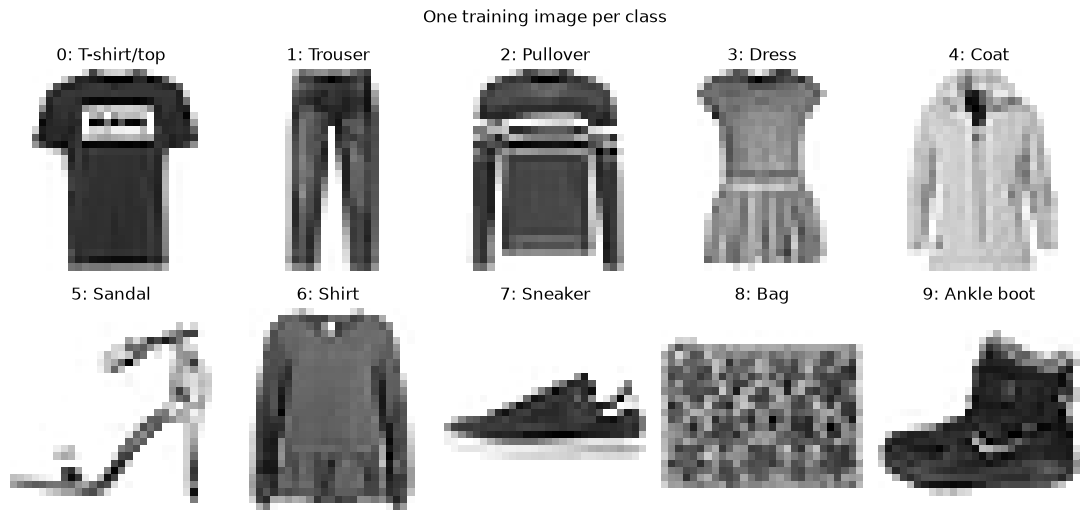

In [23]:
# One training image per class, to see what the model has to tell apart
fig, axes = plt.subplots(2, 5, figsize=(11, 5.5))
for label, ax in enumerate(axes.flat):
    ax.imshow(X_train_full[y_train_full == label][0], cmap='gray_r')  # first training image with this label, gray_r = dark garment on white
    ax.set_title(f"{label}: {class_names[label]}")
    ax.axis('off')
plt.suptitle('One training image per class')
plt.tight_layout()
plt.show()

Every class has exactly 6,000 training and 1,000 test images, so the classes are **balanced**. Unlike assignment 2, where always guessing "no diabetes" was already 86% accurate, always predicting one class here would only be 10% accurate, so accuracy is a meaningful overall measure (though it still hides which classes are hard, see Part C).

The example images also show which classes could be hard to tell apart: T-shirt/top, pullover, coat and shirt are all tops with a similar outline, and sandal, sneaker and ankle boot are all shoes. Trousers and bags look quite different from everything else.

In [24]:
# Normalize the pixel values from 0-255 to 0-1
X_train_full = X_train_full.astype('float32') / 255.0  # divide by the largest possible pixel value
X_test = X_test.astype('float32') / 255.0  # the same fixed formula for the test set

print(f"Pixel values now from {X_train_full.min()} to {X_train_full.max()}")

# Unlike the StandardScaler in assignments 1 and 2, nothing is learned from the data here (255 is fixed by the image format),
# so normalizing the test set at the same time can't leak any information from it

Pixel values now from 0.0 to 1.0


For flattening we keep the images as 28 × 28 arrays and put a Keras `Flatten` layer first in the model instead. It turns each image into 28 × 28 = 784 input features inside the model, and the arrays can still be plotted as images later (Part C).

### Training, validation and test data

Keras only provides a training and a test set, so we also split a fixed validation set off the training images. Each set has its own job:

- **Training set (50,000):** the models learn their weights from these.
- **Validation set (10,000):** used to compare the four models and choose one. It is never used to update any weights.
- **Test set (10,000):** used once, on the chosen model only, as in assignments 1 and 2. Since we pick the model with the best validation accuracy, that score is slightly optimistic, and the test set gives the unbiased estimate.

We split once, up front, so all four models are guaranteed to train and validate on exactly the same images.

In [25]:
# Fixed validation set, shared by all four models
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=10_000,  # 10,000 validation images, the same size as the test set
    random_state=SEED,  # the same split every time the notebook runs
    stratify=y_train_full,  # exactly 1,000 images of each class in validation, same idea as in assignment 2
)
print(f"Training: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)}")
print(f"Validation images per class: {np.unique(np.bincount(y_val))}")  # a single number means every class has the same count

# The test set is left alone from here until the chosen model is evaluated in Task 3

Training: 50000, validation: 10000, test: 10000
Validation images per class: [1000]


## Part A - Build and compare neural networks

> **Task 1.** Build a baseline model with one hidden layer of 32 neurons using ReLU activation and the Adam optimizer. Train it and record its training and validation accuracy.

All four models have the same structure and only differ in three settings, so we build them with one function. The baseline settings are stored once, and each experiment only passes the one setting it changes.

In [26]:
BASELINE = {'hidden_neurons': 32, 'activation': 'relu', 'optimizer': 'adam'}  # the baseline settings for every experiment

def build_model(hidden_neurons, activation, optimizer):
    tf.keras.utils.set_random_seed(SEED)  # same starting weights and same shuffling of the batches for every model, so only the changed setting differs
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(28, 28)),  # one 28 x 28 image
        tf.keras.layers.Flatten(),  # 28 x 28 -> 784 input features
        tf.keras.layers.Dense(hidden_neurons, activation=activation),  # the hidden layer
        tf.keras.layers.Dense(10, activation='softmax'),  # one output neuron per class, softmax turns them into probabilities
    ])
    model.compile(
        optimizer=optimizer,  # given as a string ('adam' / 'sgd'), so Keras uses its default settings
        loss='sparse_categorical_crossentropy',  # the labels are integers 0-9 (see Q2)
        metrics=['accuracy'],  # reported during training, next to the loss
    )
    return model

In [27]:
# Task 1 - Baseline: 32 hidden neurons, ReLU, Adam
baseline = build_model(**BASELINE)  # ** unpacks the dict into the three arguments
baseline.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
history = baseline.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),  # measured after every epoch, but never used to update the weights
    epochs=10,
    batch_size=64,  # 50,000 / 64 = 782 batches, so 782 weight updates per epoch
    verbose=2,  # one line per epoch
)

histories = {'Baseline': history.history}  # loss and accuracy per epoch, collected for all four models
models = {'Baseline': baseline}

print(f"\nBaseline: training accuracy {history.history['accuracy'][-1]:.4f}, validation accuracy {history.history['val_accuracy'][-1]:.4f}")

Epoch 1/10
782/782 - 3s - 4ms/step - accuracy: 0.7956 - loss: 0.6087 - val_accuracy: 0.8487 - val_loss: 0.4421
Epoch 2/10
782/782 - 2s - 3ms/step - accuracy: 0.8445 - loss: 0.4448 - val_accuracy: 0.8575 - val_loss: 0.4091
Epoch 3/10
782/782 - 2s - 3ms/step - accuracy: 0.8566 - loss: 0.4068 - val_accuracy: 0.8627 - val_loss: 0.3892
Epoch 4/10
782/782 - 3s - 4ms/step - accuracy: 0.8642 - loss: 0.3818 - val_accuracy: 0.8630 - val_loss: 0.3797
Epoch 5/10
782/782 - 2s - 3ms/step - accuracy: 0.8707 - loss: 0.3644 - val_accuracy: 0.8659 - val_loss: 0.3731
Epoch 6/10
782/782 - 2s - 3ms/step - accuracy: 0.8753 - loss: 0.3509 - val_accuracy: 0.8693 - val_loss: 0.3689
Epoch 7/10
782/782 - 2s - 2ms/step - accuracy: 0.8790 - loss: 0.3401 - val_accuracy: 0.8720 - val_loss: 0.3645
Epoch 8/10
782/782 - 2s - 2ms/step - accuracy: 0.8817 - loss: 0.3309 - val_accuracy: 0.8720 - val_loss: 0.3604
Epoch 9/10
782/782 - 2s - 2ms/step - accuracy: 0.8842 - loss: 0.3230 - val_accuracy: 0.8719 - val_loss: 0.3613
E

The baseline reaches `0.8862` training accuracy and `0.8736` validation accuracy after 10 epochs. The training loss falls every epoch, fastest in the first two, while validation accuracy levels off around 0.872 from epoch 7. Training accuracy ends 1.3 percentage points above validation accuracy, so the model fits the training images slightly better than new ones, but there is no sign of serious overfitting yet.

One detail about these numbers: the training accuracy Keras reports is the average over all batches in the epoch, measured while the weights were still changing. The validation accuracy is measured at the end of the epoch, with the final weights. So the reported training accuracy is slightly too low, which matters most while a model is still improving quickly.

> **Task 2.** Starting from the baseline, run three more experiments. For each experiment, change only the setting shown below; keep the other settings the same as the baseline.
>
> | Model | Hidden neurons | Hidden activation | Optimizer |
> |---|---|---|---|
> | Baseline | 32 | ReLU | Adam |
> | Experiment 1 | 64 | ReLU | Adam |
> | Experiment 2 | 32 | tanh | Adam |
> | Experiment 3 | 32 | ReLU | SGD |

In [29]:
# Task 2 - Three experiments, each changing exactly one setting from the baseline
experiments = {
    'Experiment 1': {'hidden_neurons': 64},  # more neurons
    'Experiment 2': {'activation': 'tanh'},  # different hidden activation
    'Experiment 3': {'optimizer': 'sgd'},  # different optimizer
}

for name, change in experiments.items():
    model = build_model(**(BASELINE | change))  # | merges the dicts: the baseline settings with the one change on top
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=10, batch_size=64, verbose=0)  # same data, epochs and batch size as the baseline, without the per-epoch log
    histories[name] = history.history
    models[name] = model
    print(f"{name} {change}: training accuracy {history.history['accuracy'][-1]:.4f}, validation accuracy {history.history['val_accuracy'][-1]:.4f}")

Experiment 1 {'hidden_neurons': 64}: training accuracy 0.8975, validation accuracy 0.8779
Experiment 2 {'activation': 'tanh'}: training accuracy 0.8916, validation accuracy 0.8842
Experiment 3 {'optimizer': 'sgd'}: training accuracy 0.8476, validation accuracy 0.8515


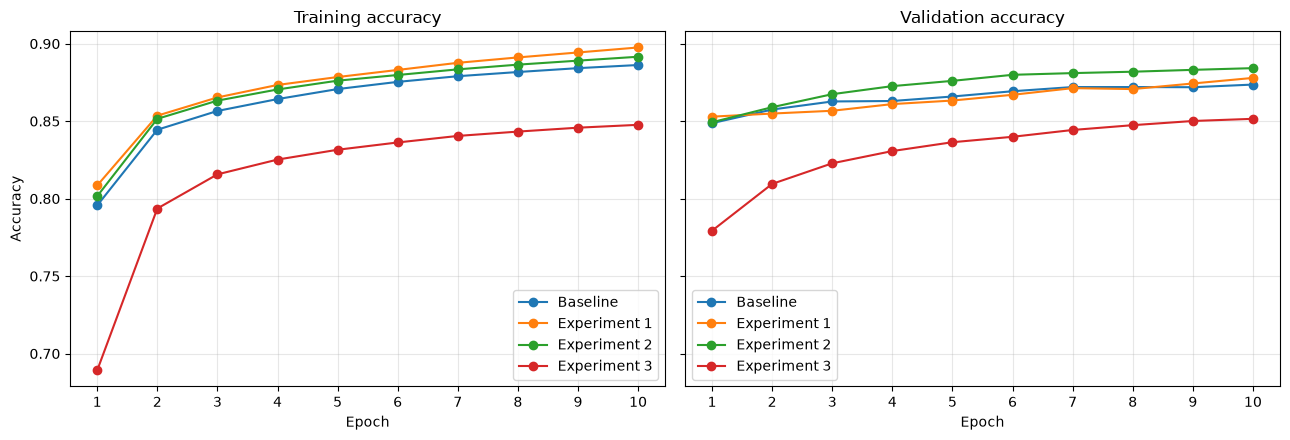

In [30]:
# Accuracy after every epoch, for all four models
epochs = range(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)  # shared y-axis, so the two panels can be compared directly
for name, h in histories.items():
    axes[0].plot(epochs, h['accuracy'], marker='o', label=name)
    axes[1].plot(epochs, h['val_accuracy'], marker='o', label=name)
axes[0].set_title('Training accuracy')
axes[1].set_title('Validation accuracy')
axes[0].set_ylabel('Accuracy')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.set_xticks(epochs)
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

- **Experiment 1 (64 neurons)** has the highest training accuracy in every epoch, but its validation accuracy is *below* the baseline's from epoch 2 to 7, and it only pulls ahead in the last three epochs.
- **Experiment 2 (tanh)** has the highest validation accuracy from epoch 2 onwards.
- **Experiment 3 (SGD)** starts far behind (`0.689` training accuracy after the first epoch, against about `0.80` for the three Adam models) and stays well below them. Its validation loss is still falling faster in the last epoch than for any of the Adam models (`0.4333` → `0.4276`), so it is still learning when training stops.
- None of the validation curves turn clearly downwards, so 10 epochs are not enough for any of the models to start overfitting badly.

> **Task 3.** Record the training and validation accuracy of all four models in a results table. Identify the model with the highest validation accuracy. Evaluate that model on the test set and report its test accuracy. Do not use the test set to choose the model.

In [31]:
# Task 3 - Results table: training and validation accuracy after the 10th epoch
rows = []
for name, h in histories.items():
    settings = BASELINE | experiments.get(name, {})  # the baseline has no entry in experiments, so it just gets BASELINE
    rows.append({
        'Model': name,
        'Hidden neurons': settings['hidden_neurons'],
        'Hidden activation': settings['activation'],
        'Optimizer': settings['optimizer'],
        'Training accuracy': h['accuracy'][-1],
        'Validation accuracy': h['val_accuracy'][-1],
    })

results = pd.DataFrame(rows).set_index('Model')
results['Training - validation'] = results['Training accuracy'] - results['Validation accuracy']  # a large gap would point to overfitting
results.round(4)

,Hidden neurons,Hidden activation,Optimizer,Training accuracy,Validation accuracy,Training - validation
Model,,,,,,
Baseline,32,relu,adam,0.8862,0.8736,0.0126
Experiment 1,64,relu,adam,0.8975,0.8779,0.0196
Experiment 2,32,tanh,adam,0.8916,0.8842,0.0074
Experiment 3,32,relu,sgd,0.8476,0.8515,-0.0039


In [32]:
# Choose the model with the highest VALIDATION accuracy. The test set plays no part in this choice
best_name = results['Validation accuracy'].idxmax()
best_model = models[best_name]
print(f"Highest validation accuracy: {best_name} ({results.loc[best_name, 'Validation accuracy']:.4f})")

# Only now is the test set used, once, on the chosen model
test_loss, test_accuracy = best_model.evaluate(X_test, y_test, verbose=0)  # returns the loss and the metrics given in compile()
print(f"{best_name} on the test set: accuracy {test_accuracy:.4f}, loss {test_loss:.4f}")

Highest validation accuracy: Experiment 2 (0.8842)
Experiment 2 on the test set: accuracy 0.8671, loss 0.3741


**Experiment 2 (tanh)** has the highest validation accuracy (`0.8842`), so we pick this as our model. On the test set it reaches a **test accuracy of `0.8671`**.

The test accuracy is 1.7 percentage points lower than the validation accuracy. Some drop is expected: we pick this model *because* it had the highest validation score out of four, which makes that score a little optimistic. The drop seems larger than that alone would explain, so the test images also seem slightly harder for the model than my validation images, which were split off from the same 60,000 images it trained on. We can't separate the two effects without using the test set for more than this one evaluation, so we just take note of it for now. The test accuracy is the number I'd report for how the model does on new images.

Experiment 3 (SGD) is the only model with a higher validation than training accuracy (`0.8517` vs `0.8476`). This is the averaging effect from Task 1: the model was still improving through its last epoch, so its epoch-average training accuracy lags behind.

## Part B - Explain your neural network

***Q1. Architecture and parameters.*** *For the baseline model (784 inputs, 32 hidden neurons and 10 outputs), calculate the number of trainable weights and biases. Explain the difference between a parameter and a hyperparameter.*

**Answer:**

Every neuron in a `Dense` layer has one weight per input and one bias.

| Layer | Weights | Biases | Total |
|---|---|---|---|
| Flatten | 0 | 0 | 0 (only reshapes) |
| Hidden (784 → 32) | 784 × 32 = 25,088 | 32 | 25,120 |
| Output (32 → 10) | 32 × 10 = 320 | 10 | 330 |
| **Total** | **25,408** | **42** | **25,450** |

This matches `Param #` in the model summary in Task 1, and the check below.

A **parameter** is a value the model learns from the training data, here the 25,450 weights and biases that the optimizer updates during `fit()`. A **hyperparameter** is a setting you choose before training, which decides how the model is built or trained: the number of hidden neurons, the activation function, the optimizer, the number of epochs and the batch size. The model can't learn these by itself, so we compare different values on the validation set instead, which is what Part A does. Changing a hyperparameter can also change the number of parameters: 64 hidden neurons give 50,890.

In [33]:
# Check the hand calculation against the weights Keras actually created
for layer_name, layer in zip(['Hidden layer', 'Output layer'], baseline.layers[1:]):  # layers[0] is Flatten, which only reshapes and has no parameters
    weights, biases = layer.get_weights()
    print(f"{layer_name}: weights {weights.shape} = {weights.size:,}, biases {biases.shape} = {biases.size}, total {weights.size + biases.size:,}")
print(f"Baseline in total: {baseline.count_params():,} trainable parameters")
print(f"Experiment 1 (64 neurons) for comparison: {models['Experiment 1'].count_params():,}")

Hidden layer: weights (784, 32) = 25,088, biases (32,) = 32, total 25,120
Output layer: weights (32, 10) = 320, biases (10,) = 10, total 330
Baseline in total: 25,450 trainable parameters
Experiment 1 (64 neurons) for comparison: 50,890


***Q2. Activation and loss.*** *Why do we use ReLU in the hidden layer and softmax in the output layer? Why is sparse categorical cross-entropy appropriate for this dataset?*

**Answer:**

**ReLU** (`max(0, x)`) makes the hidden layer non-linear. Without it, the two `Dense` layers would collapse into a single linear function of the pixels. It is also cheap to compute and doesn't flatten out for positive inputs the way tanh does, so the gradients don't shrink during backpropagation. **Softmax** turns the 10 output values into probabilities that are positive and sum to 1, which fits a problem where every image belongs to exactly one of 10 classes, and the prediction is the class with the highest probability. **Sparse categorical cross-entropy** is the loss for more than two classes ("categorical", unlike the binary target in assignment 2) when the labels are stored as integers 0-9 ("sparse") rather than as one-hot vectors. For each image it is −log(probability given to the correct class), so it is close to 0 when the model is confident and right, and large when it is confident and wrong.

***Q3. Training and Keras functions.*** *Explain the purposes of `model.compile()`, `model.fit()`, `model.evaluate()` and `model.predict()`. Briefly explain what backpropagation and the optimizer do during training.*

**Answer:**

- `compile()` prepares the model for training by setting the optimizer, the loss function and the metrics to report. It doesn't train anything.
- `fit()` trains the model. For each of the 10 epochs it goes through the training data in batches of 64, updates the weights after every batch (782 updates per epoch), and reports the validation accuracy at the end of the epoch.
- `evaluate()` computes the loss and the metrics on some data with the current weights, without changing them. Used once, on the test set in Task 3.
- `predict()` returns the model's output, the 10 softmax probabilities per image. Used for the example in Q2 and, with `argmax` to get the predicted class, for the confusion matrix in Part C.

For every batch, the model first makes its predictions (the forward pass) and computes the loss. **Backpropagation** then works backwards from the output layer using the chain rule, and computes the gradient of the loss with respect to every weight and bias: how much, and in which direction, each parameter contributed to the error. The **optimizer** uses those gradients to move every parameter a small step in the direction that reduces the loss. SGD uses one fixed learning rate for all parameters (0.01 by default in Keras), while Adam adapts the step for each parameter using running averages of its earlier gradients (default learning rate 0.001).

***Q4. Interpreting your experiments.*** *Which model achieved the highest validation accuracy? Did changing the number of neurons, activation function or optimizer always improve accuracy? Explain using your results.*

**Answer:**

Experiment 2 (tanh) had the highest validation accuracy, `0.8842` against `0.8736` for the baseline. The changes did not always improve accuracy. Doubling the hidden neurons to 64 (Experiment 1) gave the highest *training* accuracy (`0.8979`) but only a small validation gain (`0.8771`): the extra capacity mostly went into fitting the training images, and the gap between training and validation grew from 1.3 to 2.1 percentage points. Switching to SGD (Experiment 3) made the model clearly worse (`0.8517`), since with Keras' default settings it learns much more slowly than Adam and was still improving when the 10 epochs ran out. tanh came out on top here, but the three Adam models are within about 1 percentage point of each other after a single run each, so I wouldn't conclude that tanh is generally better than ReLU, only that it was the best choice for this setup.

## Part C - Understand classification errors

> Generate a confusion matrix for your selected model using the test data. Identify one pair of clothing categories the model confuses. Explain in 2-3 sentences what the confusion matrix shows that overall accuracy does not.

Test accuracy from the predictions: 0.8671


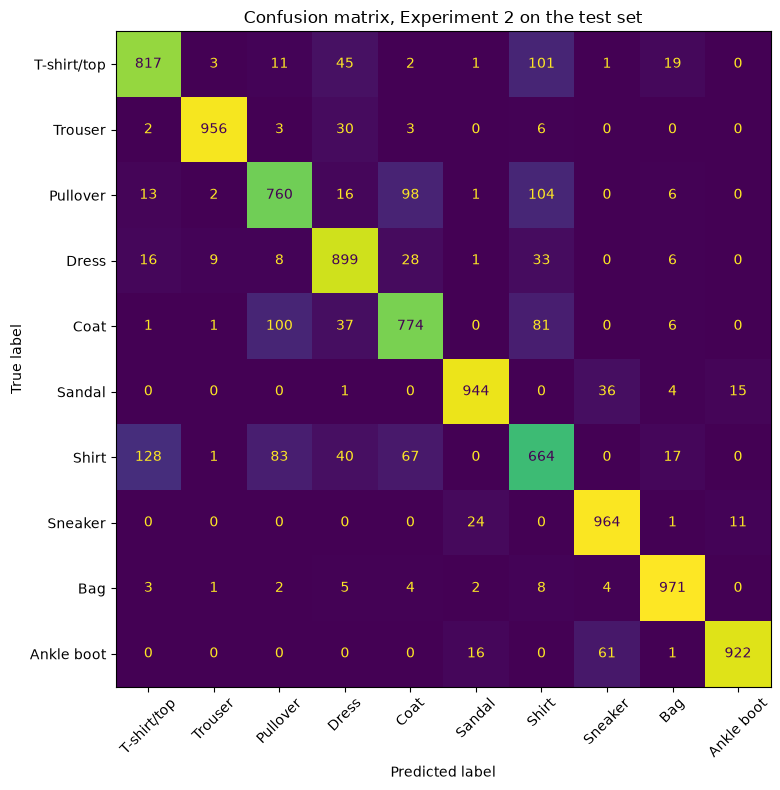

In [34]:
# Predictions of the selected model on the test set
test_probabilities = best_model.predict(X_test, verbose=0)  # shape (10000, 10): one probability per class for every image
y_pred = test_probabilities.argmax(axis=1)  # predicted class = the one with the highest probability
print(f"Test accuracy from the predictions: {(y_pred == y_test).mean():.4f}")  # should match evaluate() in Task 3

cm = confusion_matrix(y_test, y_pred)  # rows = actual class, columns = predicted class, as in assignment 2

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, values_format='d', colorbar=False, xticks_rotation=45)
ax.set_title(f'Confusion matrix, {best_name} on the test set')
plt.tight_layout()
plt.show()

In [35]:
# Accuracy per class, and each class's most common wrong prediction
mistakes = cm.copy()
np.fill_diagonal(mistakes, 0)  # keep only the errors

per_class = pd.DataFrame({
    'correct (of 1,000)': cm.diagonal(),  # the test set has 1,000 images of every class
    'accuracy': cm.diagonal() / cm.sum(axis=1),
    'most common wrong prediction': [class_names[k] for k in mistakes.argmax(axis=1)],
    'how many times': mistakes.max(axis=1),
}, index=class_names).sort_values('accuracy')
per_class.round(3)

,"correct (of 1,000)",accuracy,most common wrong prediction,how many times
Shirt,664,0.664,T-shirt/top,128
Pullover,760,0.760,Shirt,104
Coat,774,0.774,Pullover,100
T-shirt/top,817,0.817,Shirt,101
Dress,899,0.899,Shirt,33
Ankle boot,922,0.922,Sneaker,61
Sandal,944,0.944,Sneaker,36
Trouser,956,0.956,Dress,30
Sneaker,964,0.964,Sandal,24
Bag,971,0.971,Shirt,8


Most confused pair: T-shirt/top and Shirt
  T-shirt/top predicted as Shirt: 101
  Shirt predicted as T-shirt/top: 128
  229 of all 1329 test mistakes (17%)

Mistakes among the four tops: 789 (59%), among the three shoe classes: 163 (12%), between a top and a shoe: 3


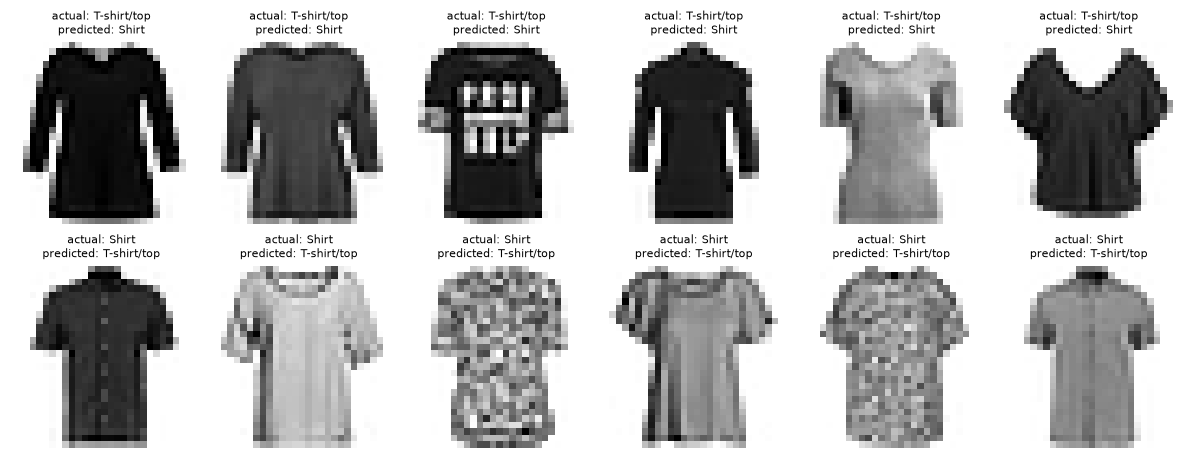

In [36]:
# The pair of classes with the most mistakes in total (A predicted as B, plus B predicted as A)
pair_mistakes = mistakes + mistakes.T  # symmetric, so each pair appears twice and argmax picks one of the two
a, b = np.unravel_index(pair_mistakes.argmax(), pair_mistakes.shape)
print(f"Most confused pair: {class_names[a]} and {class_names[b]}")
print(f"  {class_names[a]} predicted as {class_names[b]}: {mistakes[a, b]}")
print(f"  {class_names[b]} predicted as {class_names[a]}: {mistakes[b, a]}")
print(f"  {mistakes[a, b] + mistakes[b, a]} of all {mistakes.sum()} test mistakes ({(mistakes[a, b] + mistakes[b, a]) / mistakes.sum():.0%})")

# Are the mistakes spread out, or between classes that look alike?
tops = [0, 2, 4, 6]  # T-shirt/top, Pullover, Coat, Shirt
shoes = [5, 7, 9]  # Sandal, Sneaker, Ankle boot
within_tops = mistakes[np.ix_(tops, tops)].sum()  # np.ix_ picks the rows AND columns of these classes
within_shoes = mistakes[np.ix_(shoes, shoes)].sum()
between = mistakes[np.ix_(tops, shoes)].sum() + mistakes[np.ix_(shoes, tops)].sum()
print(f"\nMistakes among the four tops: {within_tops} ({within_tops / mistakes.sum():.0%}), "
      f"among the three shoe classes: {within_shoes} ({within_shoes / mistakes.sum():.0%}), "
      f"between a top and a shoe: {between}")

# What some of these mistakes look like
fig, axes = plt.subplots(2, 6, figsize=(12, 4.8))
for row, (actual, predicted) in enumerate([(a, b), (b, a)]):
    examples = np.where((y_test == actual) & (y_pred == predicted))[0][:6]  # the first six test images with this mistake
    for ax, k in zip(axes[row], examples):
        ax.imshow(X_test[k], cmap='gray_r')
        ax.set_title(f"actual: {class_names[actual]}\npredicted: {class_names[predicted]}", fontsize=8)
        ax.axis('off')
plt.tight_layout()
plt.show()

**Confused pair: T-shirt/top and Shirt.** 128 shirts were predicted as T-shirt/top and 101 T-shirts/tops as shirts, 229 mistakes in total, or 17% of all 1,329 mistakes on the test set. The examples above show why: both are tops with sleeves and almost the same outline, and at 28 × 28 pixels the details that separate a shirt from a T-shirt (buttons, a collar) are only a few pixels, if they are visible at all. Shirt is also the class the model gets right least often (66.4%).

**What the confusion matrix shows that overall accuracy does not:** The test accuracy of `0.8671` is an average over all classes, while the confusion matrix shows that the model is much better at some classes than others, from 97.1% correct for bags down to 66.4% for shirts. It also shows *where* the errors go, and that they are not random: 72% of all mistakes are between the four tops or between the three kinds of shoes, while a top and a shoe were mixed up only 3 times. So the model has learned the rough shape of each type of clothing, and struggles mainly with the finer details that separate similar ones.